# **House Price Prediction**

# **Project Overview**

House price prediction is a regression problem in Machine Learning in which a model estimates the selling price of a house based on its characteristics.

In this project, we use the Kaggle House Prices dataset to explore housing data, perform Exploratory Data Analysis (EDA), handle missing values, encode categorical features, and prepare the data for Machine Learning.

We then train and compare multiple regression models, evaluate their performance using appropriate metrics, and generate predictions for the test dataset.

# **Project Objectives**

The main objectives of this project are:

1. Understand the structure and characteristics of the dataset.
2. Perform Exploratory Data Analysis (EDA) to identify patterns and relationships.
3. Identify and handle missing values and other data quality issues.
4. Encode categorical variables and scale numerical features where required.
5. Train and compare different regression models.
6. Evaluate model performance using appropriate evaluation metrics.
7. Identify important features influencing house prices.
8. Generate predictions for the test dataset and prepare the final submission file.

# **Dataset Description**

The dataset is obtained from the Kaggle House Prices - Advanced Regression Techniques competition.

It contains information about residential properties, including their size, quality, construction year, number of rooms, garage facilities, neighborhood, and other characteristics.

The dataset is divided into two files:

- Training dataset (`train.csv`): Contains the property features and the actual sale prices. It is used for data analysis, model training, and evaluation.
- Testing dataset (`test.csv`): Contains the property features but does not include the actual sale prices. It is used to generate final predictions.

The target variable is `SalePrice`, which represents the actual selling price of a house.

# **Importing Libraries**

Python libraries provide functions for data manipulation, visualization, preprocessing, model training, and performance evaluation.

We import the required libraries at the beginning of the notebook to keep the workflow organized.

In [ ]:
# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data types and categorical data
from pandas.api.types import CategoricalDtype
import calendar

# Data preprocessing
from sklearn.preprocessing import StandardScaler

# Model evaluation and cross-validation
from sklearn.model_selection import KFold, cross_val_score

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_squared_log_error
)

# Warnings and visualization settings
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# Reproducibility
np.random.seed(42)

# **Loading the Dataset**

The next step is to load the training and testing datasets into Pandas DataFrames.

The training data will be used to understand the features and their relationships with house prices. The testing data will be used later to generate predictions.

We will keep the training and testing datasets separate during exploratory analysis and model preprocessing to avoid data leakage.

In [ ]:
df_train = pd.read_csv("/content/drive/MyDrive/Data Science Projeccts/House Price Prediction/data/train.csv")
df_test =pd.read_csv("/content/drive/MyDrive/Data Science Projeccts/House Price Prediction/data/test.csv")

# **Initial Data Inspection**

Before performing EDA or preprocessing, we need to understand the dataset's structure, dimensions, column names, data types, and general characteristics.

This initial inspection helps identify potential data quality issues and guides the next steps.

In [ ]:
print("Shape of Training data :",df_train.shape)
print("Shape of Testing data :",df_test.shape)

Shape of Training data : (1460, 81)
Shape of Testing data : (1459, 80)


In [ ]:
# To See all the columns and rows without skipping
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

## Display Training and Testing Data

In [ ]:
df_train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
df_test.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,6,1998,1998,Gable,CompShg,VinylSd,VinylSd,BrkFace,20.0,TA,TA,PConc,TA,TA,No,GLQ,602.0,Unf,0.0,324.0,926.0,GasA,Ex,Y,SBrkr,926,678,0,1604,0.0,0.0,2,1,3,1,Gd,7,Typ,1,Gd,Attchd,1998.0,Fin,2.0,470.0,TA,TA,Y,360,36,0,0,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,Inside,Gtl,StoneBr,Norm,Norm,TwnhsE,1Story,8,5,1992,1992,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,Gd,TA,PConc,Gd,TA,No,ALQ,263.0,Unf,0.0,1017.0,1280.0,GasA,Ex,Y,SBrkr,1280,0,0,1280,0.0,0.0,2,0,2,1,Gd,5,Typ,0,NaN,Attchd,1992.0,RFn,2.0,506.0,TA,TA,Y,0,82,0,0,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


### **Display Dataset Information**

In [ ]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

**Statistical Summary of Numerical Features**

In [ ]:
df_train.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


## **Exploratory Data Analysis (EDA)**

Exploratory Data Analysis (EDA) is the process of examining and visualizing data to understand its structure, distribution, patterns, and relationships between variables.

In this project, EDA helps us understand the distribution of house prices, identify missing values, examine relationships between features, and determine which factors may influence the sale price of a house.

Important Features:

*   Neighbourhood
*   Overallqual
*   Overallqual
*   Overallcond
*   YearBuilt
*   Electrical
*   Foundation
*   KitchenQual
*   GarageType
*   GarageFinish












In [ ]:
df_train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
# Summary Statistics of SalePrice
df_train["SalePrice"].describe()

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


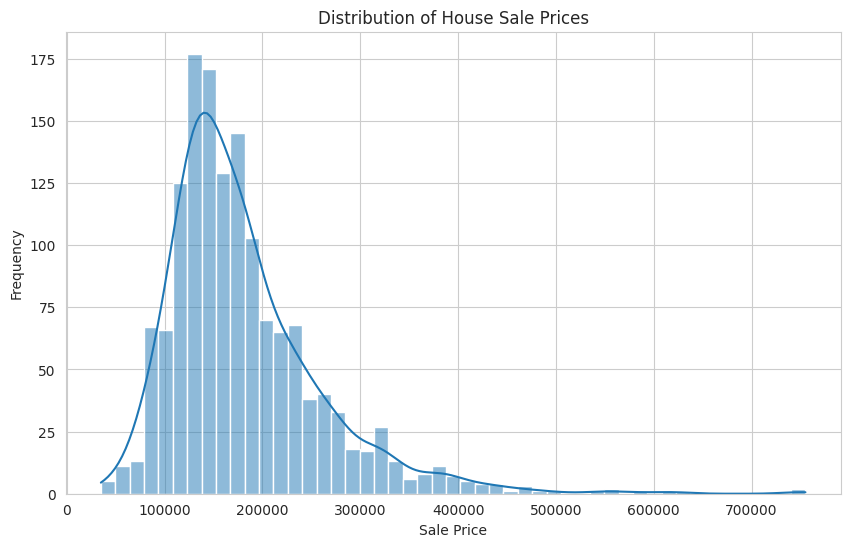

In [ ]:
# Distribution of SalePrice

plt.figure(figsize=(10, 6))

sns.histplot(data=df_train, x="SalePrice", kde=True)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()

**Interpretation:**

In this dataset, house prices are generally right-skewed. Most houses fall within lower-to-middle price ranges, while a smaller number of houses have considerably higher prices.

In [ ]:
# Calculate Skewness
print("SalePrice Skewness:", df_train["SalePrice"].skew())

SalePrice Skewness: 1.8828757597682129


# **Data Integration**

Integrating Training and Testing data to perform certain preprocessing operations

In [ ]:
df_integrated = pd.concat([df_train, df_test])
df_integrated.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706.0,Unf,0.0,150.0,856.0,GasA,Ex,Y,SBrkr,856,854,0,1710,1.0,0.0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2.0,548.0,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500.0
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978.0,Unf,0.0,284.0,1262.0,GasA,Ex,Y,SBrkr,1262,0,0,1262,0.0,1.0,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2.0,460.0,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500.0
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486.0,Unf,0.0,434.0,920.0,GasA,Ex,Y,SBrkr,920,866,0,1786,1.0,0.0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2.0,608.0,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500.0
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216.0,Unf,0.0,540.0,756.0,GasA,Gd,Y,SBrkr,961,756,0,1717,1.0,0.0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3.0,642.0,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000.0
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655.0,Unf,0.0,490.0,1145.0,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1.0,0.0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3.0,836.0,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000.0


In [ ]:
print("Shape of Integrated dataset is ", df_integrated.shape)

Shape of Integrated dataset is  (2919, 81)


# **Data Preprocessing**

Data preprocessing involves cleaning and transforming raw data into a suitable format for machine learning. It includes handling missing values, encoding categorical variables, scaling numerical features, and preparing data for model training.

In [ ]:
df_integrated.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2919 entries, 0 to 1458
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             2919 non-null   int64  
 1   MSSubClass     2919 non-null   int64  
 2   MSZoning       2915 non-null   object 
 3   LotFrontage    2433 non-null   float64
 4   LotArea        2919 non-null   int64  
 5   Street         2919 non-null   object 
 6   Alley          198 non-null    object 
 7   LotShape       2919 non-null   object 
 8   LandContour    2919 non-null   object 
 9   Utilities      2917 non-null   object 
 10  LotConfig      2919 non-null   object 
 11  LandSlope      2919 non-null   object 
 12  Neighborhood   2919 non-null   object 
 13  Condition1     2919 non-null   object 
 14  Condition2     2919 non-null   object 
 15  BldgType       2919 non-null   object 
 16  HouseStyle     2919 non-null   object 
 17  OverallQual    2919 non-null   int64  
 18  OverallCond  

**Most Null Value Feature we got from brief information**

*   Alley
*   FireplaceQu
*   PoolQc
*   Fence
*   MiscFeature





In [ ]:
int_features = df_integrated.select_dtypes(include=['int64']).columns
print("Total number of Integer features ", int_features.shape[0])
print("Integer Feature Names ", int_features.tolist())


Total number of Integer features  26
Integer Feature Names  ['Id', 'MSSubClass', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']


In [ ]:
float_features = df_integrated.select_dtypes(include=['float64']).columns
print("Total number of Float features ", float_features.shape[0])
print("Float Feature Names ", float_features.tolist())

Total number of Float features  12
Float Feature Names  ['LotFrontage', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'SalePrice']


In [ ]:
cat_features = df_integrated.select_dtypes(include=['object']).columns
print("Total number of Categorical features ", cat_features.shape[0])
print("Categorical Feature Names ", cat_features.tolist())

Total number of Categorical features  43
Categorical Feature Names  ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


**Data Preprocessing: Statistical Infomation of Numerical Features**

In [ ]:
df_integrated.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,2919.000000,2919.000000,2433.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2896.000000,2918.000000,2918.000000,2918.000000,2918.000000,2919.000000,2919.000000,2919.000000,2919.000000,2917.000000,2917.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2760.000000,2918.000000,2918.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,1460.000000
mean,1460.000000,57.137718,69.305795,10168.114080,6.089072,5.564577,1971.312778,1984.264474,102.201312,441.423235,49.582248,560.772104,1051.777587,1159.581706,336.483727,4.694416,1500.759849,0.429894,0.061364,1.568003,0.380267,2.860226,1.044536,6.451524,0.597122,1978.113406,1.766621,472.874572,93.709832,47.486811,23.098321,2.602261,16.062350,2.251799,50.825968,6.213087,2007.792737,180921.195890
std,842.787043,42.517628,23.344905,7886.996359,1.409947,1.113131,30.291442,20.894344,179.334253,455.610826,169.205611,439.543659,440.766258,392.362079,428.701456,46.396825,506.051045,0.524736,0.245687,0.552969,0.502872,0.822693,0.214462,1.569379,0.646129,25.574285,0.761624,215.394815,126.526589,67.575493,64.244246,25.188169,56.184365,35.663946,567.402211,2.714762,1.314964,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1895.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,730.500000,20.000000,59.000000,7478.000000,5.000000,5.000000,1953.500000,1965.000000,0.000000,0.000000,0.000000,220.000000,793.000000,876.000000,0.000000,0.000000,1126.000000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1960.000000,1.000000,320.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129975.000000
50%,1460.000000,50.000000,68.000000,9453.000000,6.000000,5.000000,1973.000000,1993.000000,0.000000,368.500000,0.000000,467.000000,989.500000,1082.000000,0.000000,0.000000,1444.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1979.000000,2.000000,480.000000,0.000000,26.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,2189.500000,70.000000,80.000000,11570.000000,7.000000,6.000000,2001.000000,2004.000000,164.000000,733.000000,0.000000,805.500000,1302.000000,1387.500000,704.000000,0.000000,1743.500000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,2919.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1526.000000,2336.000000,6110.000000,5095.000000,2065.000000,1064.000000,5642.000000,3.000000,2.000000,4.000000,2.000000,8.000000,3.000000,15.000000,4.000000,2207.000000,5.000000,1488.000000,1424.000000,742.000000,1012.000000,508.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000,755000.000000


**Data Preprocessing: Handling Missing Values**

In [ ]:
df_integrated = df_integrated.set_index("Id")

In [ ]:
null_count = df_integrated.isnull().sum()
null_count

,0
MSSubClass,0
MSZoning,4
LotFrontage,486
LotArea,0
Street,0
Alley,2721
LotShape,0
LandContour,0
Utilities,2
LotConfig,0


In [ ]:
# Percentage of Null Values in each Column
null_percent = df_integrated.isnull().sum() / df_integrated.shape[0] * 100
null_percent

,0
MSSubClass,0.000000
MSZoning,0.137033
LotFrontage,16.649538
LotArea,0.000000
Street,0.000000
Alley,93.216855
LotShape,0.000000
LandContour,0.000000
Utilities,0.068517
LotConfig,0.000000


**Data Preprocessing:  Deciding to Drop Features or Not as per the Observation**

In [ ]:
# Identifying Features that have more than 50% missing values.
miss_value_50_per = null_percent[null_percent > 50]
miss_value_50_per

,0
Alley,93.216855
MasVnrType,60.500171
PoolQC,99.657417
Fence,80.438506
MiscFeature,96.402878


In [ ]:
df_integrated["Alley"].value_counts()
# As per domain knowledge we will not drop this feature instead we will replace null value with a constant 'NA'

,count
Alley,
Grvl,120
Pave,78


In [ ]:
# Identifying Features that have missing values more than 20% and less than 50%.
miss_value_20_50_per = null_percent[(null_percent > 20) & (null_percent < 50)]
miss_value_20_50_per

,0
FireplaceQu,48.646797
SalePrice,49.982871


In [ ]:
df_integrated["FireplaceQu"].value_counts()
# As per domain knowledge we will not drop this feature instead we will replace null value with a constant 'NA'

,count
FireplaceQu,
Gd,744
TA,592
Fa,74
Po,46
Ex,43


In [ ]:
# Identifying Features that have missing values more than 20% and less than 50%.
miss_value_5_20_per = null_percent[(null_percent > 5) & (null_percent < 20)]
miss_value_5_20_per

,0
LotFrontage,16.649538
GarageType,5.378554
GarageYrBlt,5.447071
GarageFinish,5.447071
GarageQual,5.447071
GarageCond,5.447071


**Data Preprocessing: Missing Value Imputation**

In [ ]:
miss_value_feat = null_percent[null_percent > 0]
print("Total Number of Missing Values : ",len(miss_value_feat))

Total Number of Missing Values :  35


In [ ]:
cat_nul_features = miss_value_feat[miss_value_feat.keys().isin(cat_features)]
print("Total Number of Categorical Missing Values : ",len(cat_nul_features))
cat_nul_features

Total Number of Categorical Missing Values :  23


,0
MSZoning,0.137033
Alley,93.216855
Utilities,0.068517
Exterior1st,0.034258
Exterior2nd,0.034258
MasVnrType,60.500171
BsmtQual,2.774923
BsmtCond,2.809181
BsmtExposure,2.809181
BsmtFinType1,2.706406


In [ ]:
int_nul_features = miss_value_feat[miss_value_feat.keys().isin(int_features)]
print("Total Number of Integer Missing Values : ",len(int_nul_features))

Total Number of Integer Missing Values :  0


In [ ]:
float_nul_features = miss_value_feat[miss_value_feat.keys().isin(float_features)]
print("Total Number of Float Missing Values : ",len(float_nul_features))

Total Number of Float Missing Values :  12


**Handling Categorical Features**


1.   MSZoning



In [ ]:
df_integrated["MSZoning"].value_counts()

,count
MSZoning,
RL,2265
RM,460
FV,139
RH,26
C (all),25


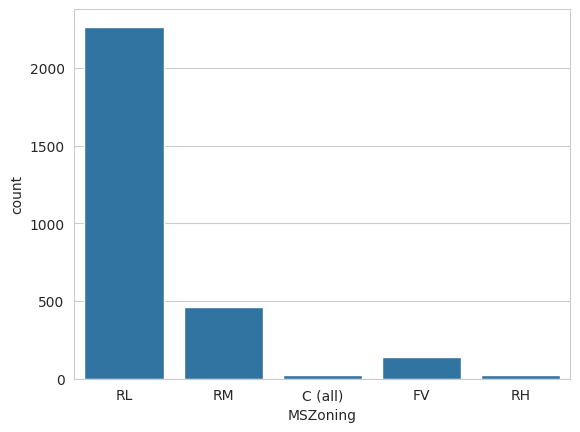

In [ ]:
sns.countplot(data=df_integrated, x="MSZoning")
plt.show()


In categorical data we replace null values with Mode. Above in the counterplot we can see that RL is the most featured category or value, so we fill the missing values with RL.

In [ ]:
# Created copy of original dataframe to fill missing values and other operations.
df_integrated_mvi = df_integrated.copy()
df_integrated_mvi.shape

(2919, 80)

In [ ]:
# Calculating the mode of this category, so we can use it.
mszoning_mode = df_integrated["MSZoning"].mode()[0]
mszoning_mode

'RL'

In [ ]:
# Filling null values of this category with the mode.
df_integrated_mvi["MSZoning"] = df_integrated_mvi["MSZoning"].fillna(mszoning_mode)
df_integrated_mvi["MSZoning"].isnull().sum()

np.int64(0)

**Handling Alley = 93.216855**

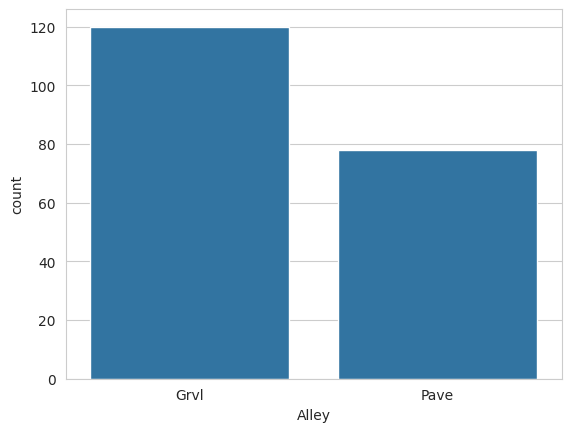

In [ ]:
sns.countplot(data=df_integrated_mvi, x="Alley")
plt.show()

In [ ]:
df_integrated_mvi["Alley"].value_counts()

,count
Alley,
Grvl,120
Pave,78


In [ ]:
df_integrated_mvi["Alley"].isna().sum()

np.int64(2721)

In [ ]:
# Filling null values of this category with the constant NA.
alley_const = "NA"
df_integrated_mvi["Alley"] = df_integrated_mvi["Alley"].fillna(alley_const)
df_integrated_mvi["Alley"].isna().sum()

np.int64(0)

In [ ]:
def old_new_countplot(df_integrated, df_integrated_mvi, feature):
  plt.subplot(121)
  sns.countplot(x = df_integrated[feature])   # Using x=... to get the graph in vertical otherwise it gives it in horizontal.
  plt.title("Before Imputation")
  plt.subplot(122)
  sns.countplot(x = df_integrated_mvi[feature])
  plt.title("After Imputation")
  plt.tight_layout()
  plt.show()

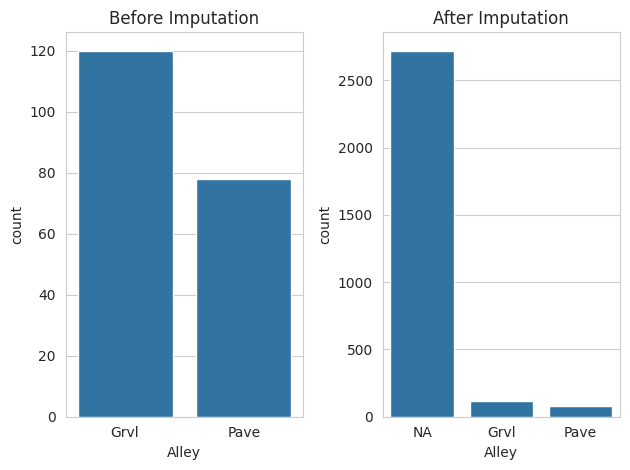

In [ ]:
old_new_countplot(df_integrated, df_integrated_mvi, "Alley")

**Handling LotFrontage 16.649538 : Numerical feature**


---


We usually fill null values of numerical features with mean or median.

In [ ]:
df_integrated_mvi["LotFrontage"].info()

<class 'pandas.core.series.Series'>
Index: 2919 entries, 1 to 2919
Series name: LotFrontage
Non-Null Count  Dtype  
--------------  -----  
2433 non-null   float64
dtypes: float64(1)
memory usage: 45.6 KB


In [ ]:
def boxhistplot_1(feature):
  plt.figure(figsize =(16, 5))
  plt.subplot(121)
  sns.boxplot(x=df_integrated_mvi[feature])

  plt.subplot(122)
  sns.histplot(x=df_integrated_mvi[feature], kde=True)
  plt.tight_layout()
  plt.show()

We visualize the distribution of data, if the data is normally distributed then we replace the null values with mean, and if the data is right skewed or left skewed then we replace the null values with median.

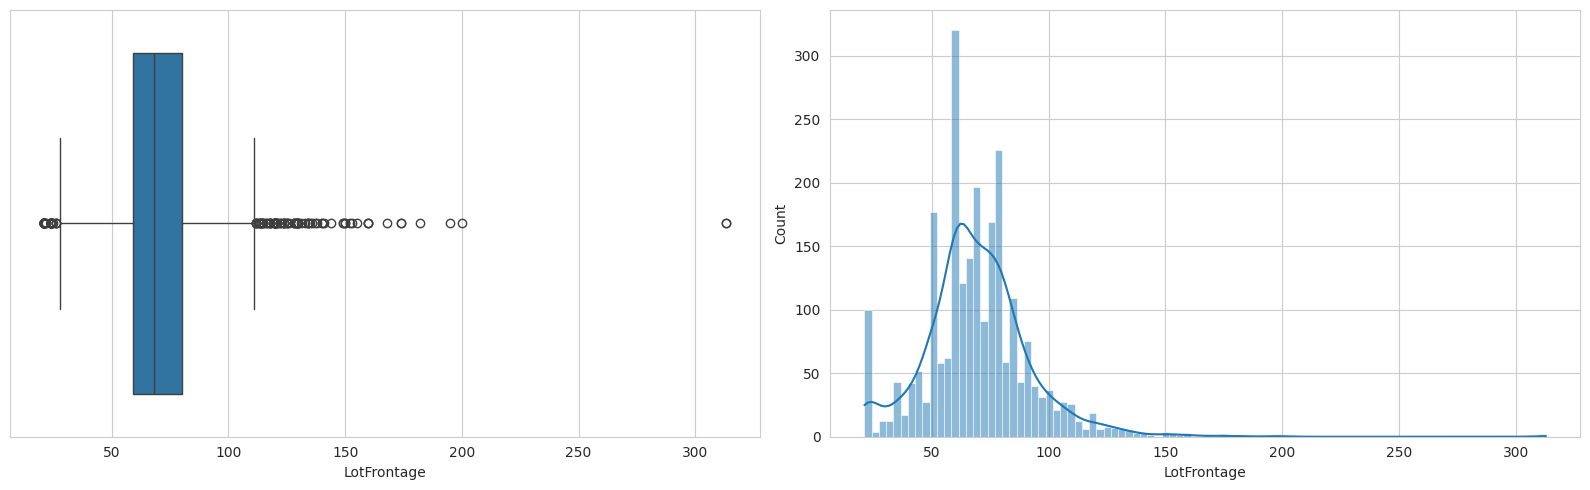

In [ ]:
boxhistplot_1("LotFrontage")

Above in the graphs we can see distributon of data is right skewed therefore we take the median value.

In [ ]:
lot_frontage_median = df_integrated_mvi["LotFrontage"].median()
df_integrated_mvi["LotFrontage"] = df_integrated_mvi["LotFrontage"].fillna(lot_frontage_median)
df_integrated_mvi["LotFrontage"].isna().sum()

np.int64(0)

In [ ]:
def boxhistplot(df_integrated, df_integrated_mvi, feature):
  plt.figure(figsize =(12, 5))

  plt.subplot(221)
  sns.boxplot(x=df_integrated[feature])
  plt.title("Before Imputation")

  plt.subplot(222)
  sns.histplot(x=df_integrated[feature], kde=True)
  plt.title("Before Imputation")

  plt.subplot(223)
  sns.boxplot(x=df_integrated_mvi[feature])
  plt.title("After Imputation")

  plt.subplot(224)
  sns.histplot(x=df_integrated_mvi[feature], kde=True)
  plt.title("After Imputation")

  plt.tight_layout()
  plt.show()

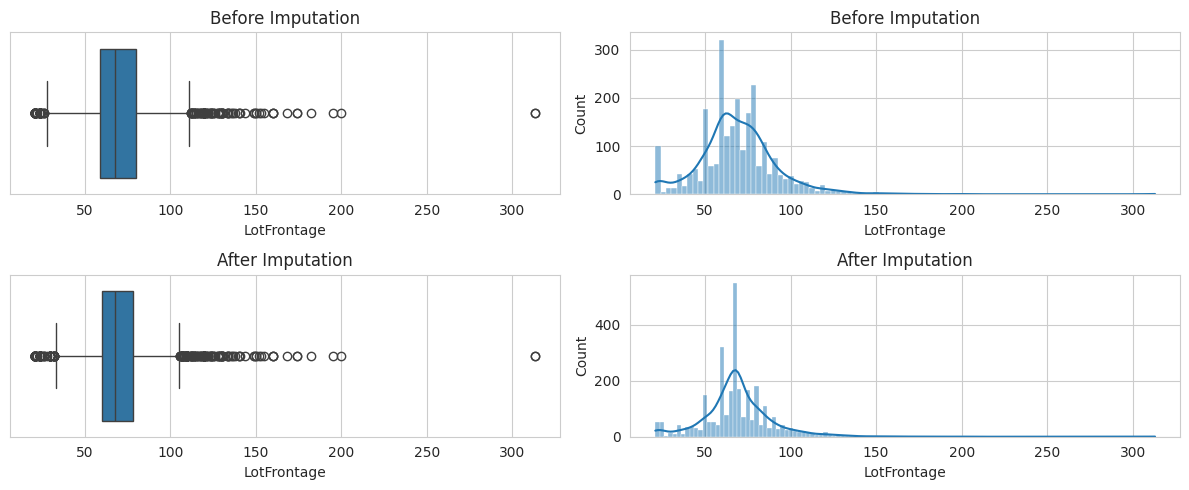

In [ ]:
boxhistplot(df_integrated, df_integrated_mvi, "LotFrontage")

**Handling Utilities = 0.068517**

In [ ]:
df_integrated_mvi["Utilities"].info()


<class 'pandas.core.series.Series'>
Index: 2919 entries, 1 to 2919
Series name: Utilities
Non-Null Count  Dtype 
--------------  ----- 
2917 non-null   object
dtypes: object(1)
memory usage: 45.6+ KB


In [ ]:
df_integrated_mvi["Utilities"].value_counts()

,count
Utilities,
AllPub,2916
NoSeWa,1


In [ ]:
df_integrated_mvi["Utilities"].isnull().sum()

np.int64(2)

In [ ]:
utility_mode = df_integrated_mvi["Utilities"].mode()[0]
df_integrated_mvi["Utilities"] = df_integrated_mvi["Utilities"].fillna(utility_mode)
df_integrated_mvi["Utilities"] = df_integrated_mvi["Utilities"].replace('utility_mode', utility_mode)
df_integrated_mvi["Utilities"].isna().sum()

np.int64(0)

In [ ]:
df_integrated_mvi["Utilities"].mode()[0]

'AllPub'

In [ ]:
df_integrated_mvi["Utilities"].unique()

array(['AllPub', 'NoSeWa'], dtype=object)

In [ ]:
null_percent

,0
MSSubClass,0.000000
MSZoning,0.137033
LotFrontage,16.649538
LotArea,0.000000
Street,0.000000
Alley,93.216855
LotShape,0.000000
LandContour,0.000000
Utilities,0.068517
LotConfig,0.000000


**Handling: Exterior1st = 0.034258, Exterior2nd = 0.034258**

In [ ]:
df_integrated_mvi["Exterior1st"].value_counts()

,count
Exterior1st,
VinylSd,1025
MetalSd,450
HdBoard,442
Wd Sdng,411
Plywood,221
CemntBd,126
BrkFace,87
WdShing,56
AsbShng,44


In [ ]:
exterist_mode = df_integrated_mvi["Exterior1st"].mode()[0]
df_integrated_mvi["Exterior1st"] = df_integrated_mvi["Exterior1st"].fillna(exterist_mode)


In [ ]:
df_integrated_mvi["Exterior1st"].isna().sum()

np.int64(0)

In [ ]:
df_integrated_mvi["Exterior2nd"].value_counts()

,count
Exterior2nd,
VinylSd,1014
MetalSd,447
HdBoard,406
Wd Sdng,391
Plywood,270
CmentBd,126
Wd Shng,81
BrkFace,47
Stucco,47


In [ ]:
exter2nd_mode = df_integrated_mvi["Exterior2nd"].mode()[0]
df_integrated_mvi["Exterior2nd"] = df_integrated_mvi["Exterior2nd"].fillna(exter2nd_mode)

In [ ]:
df_integrated_mvi["Exterior2nd"].isna().sum()

np.int64(0)

**Handling MasVnrType	1766(Categorical) and MasVnrArea	23 (Numerical)**

In [ ]:
df_integrated_mvi["MasVnrType"].value_counts()

,count
MasVnrType,
BrkFace,879
Stone,249
BrkCmn,25


In [ ]:
masvnrtype_mode = df_integrated_mvi["MasVnrType"].mode()[0]
df_integrated_mvi["MasVnrType"] = df_integrated_mvi["MasVnrType"].fillna(masvnrtype_mode)
df_integrated_mvi["MasVnrType"].isna().sum()

np.int64(0)

In [ ]:
df_integrated_mvi["MasVnrArea"].value_counts()

,count
MasVnrArea,
0.0,1738
120.0,15
200.0,13
176.0,13
216.0,12
180.0,12
108.0,11
72.0,11
16.0,11


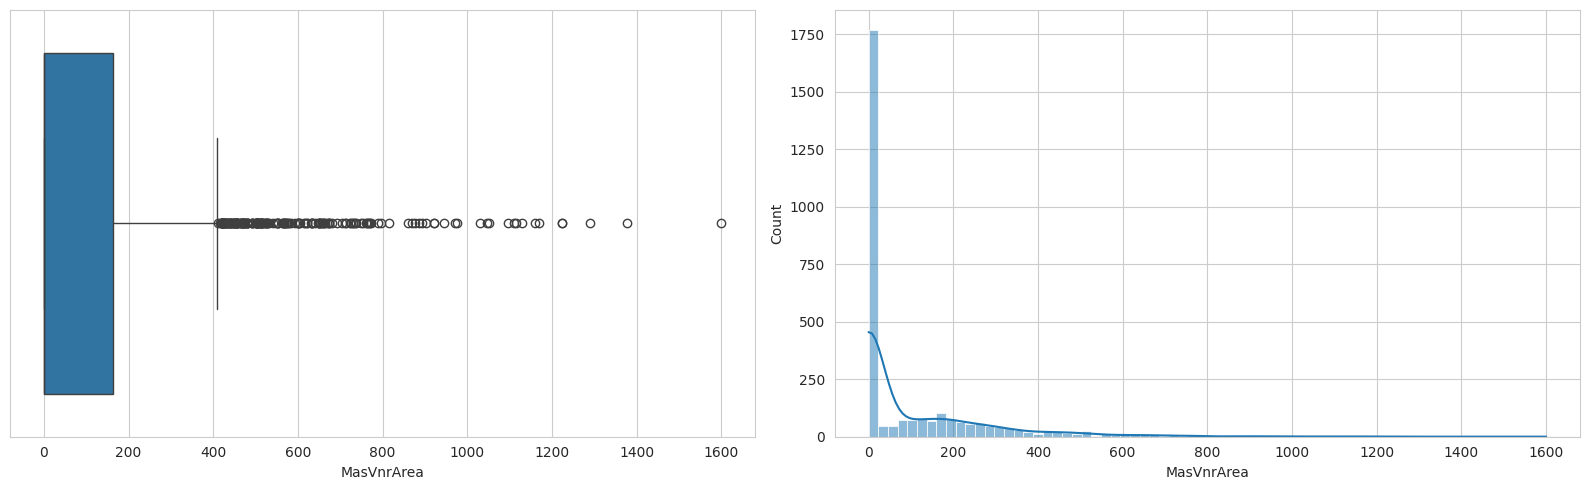

In [ ]:
boxhistplot_1("MasVnrArea")

**It can be seen in the graph that maximum values in this feature are 0. So we fill null values with 0.**

In [ ]:
masvnrarea_const = 0
df_integrated_mvi["MasVnrArea"] = df_integrated_mvi["MasVnrArea"].fillna(masvnrarea_const)
df_integrated_mvi["MasVnrArea"].isna().sum()

np.int64(0)

**Handling Basement Features**



1.   Categorical bsmt features

*   BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2


2.   Numerical bsmt features


*   'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath'






In [ ]:
cat_bsmt_feat = ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']

num_bsmt_feat = ['BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath']

<Axes: ylabel='Id'>

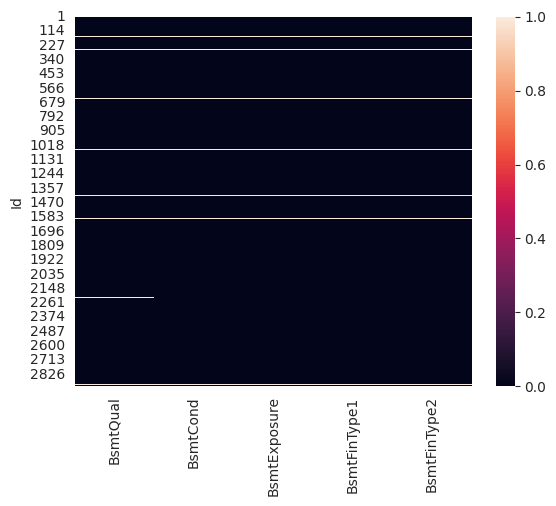

In [ ]:
sns.heatmap(df_integrated_mvi[cat_bsmt_feat].isnull())

In [ ]:
for feat in cat_bsmt_feat:
  print(f"Value Counts of {df_integrated_mvi[feat].value_counts()}")

Value Counts of BsmtQual
TA    1283
Gd    1209
Ex     258
Fa      88
Name: count, dtype: int64
Value Counts of BsmtCond
TA    2606
Gd     122
Fa     104
Po       5
Name: count, dtype: int64
Value Counts of BsmtExposure
No    1904
Av     418
Gd     276
Mn     239
Name: count, dtype: int64
Value Counts of BsmtFinType1
Unf    851
GLQ    849
ALQ    429
Rec    288
BLQ    269
LwQ    154
Name: count, dtype: int64
Value Counts of BsmtFinType2
Unf    2493
Rec     105
LwQ      87
BLQ      68
ALQ      52
GLQ      34
Name: count, dtype: int64


In [ ]:
df_integrated_mvi[cat_bsmt_feat].isnull().sum()


,0
BsmtQual,81
BsmtCond,82
BsmtExposure,82
BsmtFinType1,79
BsmtFinType2,80


In [ ]:
bsmnt_const = "NA"
for feat in cat_bsmt_feat:
  df_integrated_mvi = df_integrated_mvi.fillna({feat:bsmnt_const})

In [ ]:
df_integrated_mvi[cat_bsmt_feat].isnull().sum()


,0
BsmtQual,0
BsmtCond,0
BsmtExposure,0
BsmtFinType1,0
BsmtFinType2,0


**Now Handling Numerical Basement Features**

In [ ]:
df_basement = df_integrated[cat_bsmt_feat + num_bsmt_feat]
df_basement[df_basement.isnull().any(axis=1)]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,BsmtFullBath,BsmtHalfBath
Id,,,,,,,,,,,
18,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0
40,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0
91,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0
103,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0
157,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0
183,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0
260,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0
333,Gd,TA,No,GLQ,NaN,1124.0,479.0,1603.0,3206.0,1.0,0.0
343,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
bsmnt_num = 0
for feat in num_bsmt_feat:
  df_integrated_mvi = df_integrated_mvi.fillna({feat:bsmnt_num})

In [ ]:
df_integrated_mvi[num_bsmt_feat].isnull().sum()

,0
BsmtFinSF1,0
BsmtFinSF2,0
BsmtUnfSF,0
TotalBsmtSF,0
BsmtFullBath,0
BsmtHalfBath,0


**Handling: Electrical	0.034258 and KitchenQual	0.034258**

In [ ]:
df_integrated_mvi["Electrical"].value_counts()

,count
Electrical,
SBrkr,2671
FuseA,188
FuseF,50
FuseP,8
Mix,1


In [ ]:
df_integrated_mvi["Electrical"].isna().sum()

np.int64(1)

In [ ]:
electrical_mode = df_integrated_mvi["Electrical"].mode()[0]
df_integrated_mvi["Electrical"] = df_integrated_mvi["Electrical"].fillna(electrical_mode)

In [ ]:
df_integrated_mvi["KitchenQual"].value_counts()

,count
KitchenQual,
TA,1492
Gd,1151
Ex,205
Fa,70


In [ ]:
df_integrated_mvi["KitchenQual"].isna().sum()

np.int64(1)

In [ ]:
kitchenqual_mode = df_integrated_mvi["KitchenQual"].mode()[0]
df_integrated_mvi["KitchenQual"] = df_integrated_mvi["KitchenQual"].fillna(kitchenqual_mode)

**Handling remaining categorical values Functional	0.068517**


In [ ]:
df_integrated_mvi["Functional"].value_counts()

,count
Functional,
Typ,2717
Min2,70
Min1,65
Mod,35
Maj1,19
Maj2,9
Sev,2


In [ ]:
df_integrated_mvi["Functional"].isnull().sum()

np.int64(2)

In [ ]:
functional_mode = df_integrated_mvi["Functional"].mode()[0]
df_integrated_mvi["Functional"] = df_integrated_mvi["Functional"].fillna(functional_mode)

**Handling: Sale Type**

In [ ]:
df_integrated_mvi["SaleType"].value_counts()

,count
SaleType,
WD,2525
New,239
COD,87
ConLD,26
CWD,12
ConLI,9
ConLw,8
Oth,7
Con,5


In [ ]:
df_integrated_mvi["SaleType"].isnull().sum()

np.int64(1)

In [ ]:
saletype_mode = df_integrated_mvi["SaleType"].mode()[0]
df_integrated_mvi["SaleType"] = df_integrated_mvi["SaleType"].fillna(saletype_mode)

**Handling other categorical features with constant NA**
1. FireplaceQu	48.646797 --> NA
2. PoolQC	99.657417        --> NA
3. Fence	80.438506       --> NA
4. MiscFeature	96.402878 --> NA

In [ ]:
other_cat_feat =["FireplaceQu", "PoolQC", "Fence", "MiscFeature"]

for feat in other_cat_feat:
  print("Value count : ", df_integrated_mvi[feat].value_counts())

Value count :  FireplaceQu
Gd    744
TA    592
Fa     74
Po     46
Ex     43
Name: count, dtype: int64
Value count :  PoolQC
Ex    4
Gd    4
Fa    2
Name: count, dtype: int64
Value count :  Fence
MnPrv    329
GdPrv    118
GdWo     112
MnWw      12
Name: count, dtype: int64
Value count :  MiscFeature
Shed    95
Gar2     5
Othr     4
TenC     1
Name: count, dtype: int64


In [ ]:

for feat in other_cat_feat:
  print(f"Number of missing value in {feat} is : {df_integrated_mvi[feat].isnull().sum()}")

Number of missing value in FireplaceQu is : 1420
Number of missing value in PoolQC is : 2909
Number of missing value in Fence is : 2348
Number of missing value in MiscFeature is : 2814


In [ ]:
# Filling all with the constant NA
other_cat_feat_const = "NA"

for feat in other_cat_feat:
  df_integrated_mvi[feat]= df_integrated_mvi[feat].fillna(other_cat_feat_const)

In [ ]:
for feat in other_cat_feat:
  print(f"Number of missing value in {feat} is : {df_integrated_mvi[feat].isnull().sum()}")

Number of missing value in FireplaceQu is : 0
Number of missing value in PoolQC is : 0
Number of missing value in Fence is : 0
Number of missing value in MiscFeature is : 0


In [ ]:
null_percent

,0
MSSubClass,0.000000
MSZoning,0.137033
LotFrontage,16.649538
LotArea,0.000000
Street,0.000000
Alley,93.216855
LotShape,0.000000
LandContour,0.000000
Utilities,0.068517
LotConfig,0.000000


## Handling Garage Data
**Categorical :**

GarageType	5.378554   --> NA

GarageFinish	5.447071 --> NA

GarageQual	5.447071   --> NA

GarageCond	5.447071  --> NA

**Numerical :**

GarageYrBlt	5.447071  --> 0

GarageCars	0.034258  --> 0

GarageArea	0.034258  --> 0

In [ ]:
cat_garage_feat = ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]
num_garage_feat = ["GarageYrBlt","GarageCars", "GarageArea"]

df_garage_feat = df_integrated[cat_garage_feat + num_garage_feat]
# df_garage_feat[df_garage_feat.isnull().any(axis=1)]

In [ ]:
for feat in cat_garage_feat:
  print("Value of ", df_integrated_mvi[feat].value_counts())


Value of  GarageType
Attchd     1723
Detchd      779
BuiltIn     186
Basment      36
2Types       23
CarPort      15
Name: count, dtype: int64
Value of  GarageFinish
Unf    1230
RFn     811
Fin     719
Name: count, dtype: int64
Value of  GarageQual
TA    2604
Fa     124
Gd      24
Po       5
Ex       3
Name: count, dtype: int64
Value of  GarageCond
TA    2654
Fa      74
Gd      15
Po      14
Ex       3
Name: count, dtype: int64


In [ ]:
df_integrated_mvi[cat_garage_feat].isnull().sum()

,0
GarageType,157
GarageFinish,159
GarageQual,159
GarageCond,159


In [ ]:
cat_garage_feat_constant = "NA"
for feat in cat_garage_feat:
  df_integrated_mvi[feat] = df_integrated_mvi[feat].fillna(cat_garage_feat_constant)

In [ ]:
df_integrated_mvi[cat_garage_feat].isnull().sum()

,0
GarageType,0
GarageFinish,0
GarageQual,0
GarageCond,0


In [ ]:
df_integrated_mvi[num_garage_feat].isnull().sum()

,0
GarageYrBlt,159
GarageCars,1
GarageArea,1


In [ ]:
num_garage_feat_const = 0
for feat in num_garage_feat:
  df_integrated_mvi[feat] = df_integrated_mvi[feat].fillna(num_garage_feat_const)

In [ ]:
df_integrated_mvi[num_garage_feat].isnull().sum()

,0
GarageYrBlt,0
GarageCars,0
GarageArea,0


In [ ]:
df_integrated_mvi.isnull().sum().sum()

np.int64(1459)

We have suceessfully filled or removed all the missing values. The remaing are the targets of testing data which we have to predict through our model.

# **4. Feature Transformation**

Converting numerical data into categorical data to group continuous values into meaningful ranges, making patterns easier to identify and interpret.

[ MsSubclass, YearBuilt, YearRemodAdd, GarageYrBlt, MoSold, YrSold ]

These are some numerical features that we need to convert into categorical data.

In [ ]:
for_cat_conv = ["MSSubClass", "YearBuilt", "YearRemodAdd", "GarageYrBlt", "MoSold", "YrSold"]

for feat in for_cat_conv:
  print(f"Datatype of '{feat}' is : {df_integrated_mvi[feat].dtype}")

Datatype of 'MSSubClass' is : int64
Datatype of 'YearBuilt' is : int64
Datatype of 'YearRemodAdd' is : int64
Datatype of 'GarageYrBlt' is : float64
Datatype of 'MoSold' is : int64
Datatype of 'YrSold' is : int64


In [ ]:
df_integrated_mvi[for_cat_conv].head()

,MSSubClass,YearBuilt,YearRemodAdd,GarageYrBlt,MoSold,YrSold
Id,,,,,,
1,60,2003,2003,2003.0,2,2008
2,20,1976,1976,1976.0,5,2007
3,60,2001,2002,2001.0,9,2008
4,70,1915,1970,1998.0,2,2006
5,60,2000,2000,2000.0,12,2008


We can convert MoSold to months name from January to December by using the imported library calendar.




In [ ]:
df_integrated_mvi["MoSold"].unique()

array([ 2,  5,  9, 12, 10,  8, 11,  4,  1,  7,  3,  6])

In [ ]:
calendar.month_abbr[2] # It give the name of month corresponding to the number.

'Feb'

In [ ]:
df_integrated_mvi["MoSold"] = df_integrated_mvi["MoSold"].apply(lambda x: calendar.month_abbr[x])

In [ ]:
df_integrated_mvi["MoSold"].unique()

array(['Feb', 'May', 'Sep', 'Dec', 'Oct', 'Aug', 'Nov', 'Apr', 'Jan',
       'Jul', 'Mar', 'Jun'], dtype=object)

In [ ]:
for feat in for_cat_conv:
  df_integrated_mvi[feat] = df_integrated_mvi[feat].astype(str)

# **Feature Transformation**

**Ordinal Encoding**

Converting categorical data into numerical data to make it suitable for mathematical calculations so that machine learning algorithms can process and analyze it effectively.


"ExterQual",
"ExterCond",
"BsmtQual",
"BsmtCond",
"BsmtExposure",
"BsmtFinType1",
"BsmtFinType2",
"HeatingQC",
"KitchenQual",
"FireplaceQu,
"GarageQual,
"GarageCond",
"PoolQ",
"Functional",
"GarageFinish",
"PavedDrive",
"Utilities"

These are the features that need to be converted in numeric form using encoding.

In [ ]:
# Ordinal Encoding

ord_enc = ["ExterQual",
 "ExterCond",
 "BsmtQual",
 "BsmtCond",
 "BsmtExposure",
 "BsmtFinType1",
 "BsmtFinType2",
 "HeatingQC",
 "KitchenQual",
 "FireplaceQu",
 "GarageQual",
 "GarageCond",
 "PoolQ",
 "Functional",
 "GarageFinish",
 "PavedDrive",
 "Utilities"]

print("Total number of features to be converted using ordinal encoding : ", len(ord_enc))

Total number of features to be converted using ordinal encoding :  17


**Using class 'CategoricalDtype' imported from pandas 'types'df_integrated_mvi["ExterQual"] module **

In [ ]:
# 1. ExterQual
df_integrated_mvi["ExterQual"].unique()

array(['Gd', 'TA', 'Ex', 'Fa'], dtype=object)

In [ ]:
df_integrated_mvi["ExterQual"] = df_integrated_mvi["ExterQual"].astype(CategoricalDtype(categories= ['Po','Fa','TA','Gd','Ex'], ordered=True)).cat.codes

In [ ]:
# 2. ExterCond
df_integrated_mvi["ExterCond"].unique()

array(['TA', 'Gd', 'Fa', 'Po', 'Ex'], dtype=object)

In [ ]:
df_integrated_mvi["ExterCond"] = df_integrated_mvi["ExterCond"].astype(CategoricalDtype(categories= ['Po','Fa','TA','Gd','Ex'], ordered=True)).cat.codes

In [ ]:
# 3. BsmtQual
df_integrated_mvi["BsmtQual"].unique()

array(['Gd', 'TA', 'Ex', 'NA', 'Fa'], dtype=object)

In [ ]:
df_integrated_mvi["BsmtQual"] = df_integrated_mvi["BsmtQual"].astype(CategoricalDtype(categories= ['NA','Po', 'Fa','TA','Gd','Ex'], ordered=True)).cat.codes

In [ ]:
# 4. BsmtCond
df_integrated_mvi["BsmtCond"].unique()

array(['TA', 'Gd', 'NA', 'Fa', 'Po'], dtype=object)

In [ ]:
df_integrated_mvi["BsmtCond"] = df_integrated_mvi["BsmtCond"].astype(CategoricalDtype(categories= ['NA', 'Po','Fa','TA','Gd','Ex'], ordered=True)).cat.codes

In [ ]:
# 5. BsmtExposure
df_integrated_mvi["BsmtExposure"].unique()

array(['No', 'Gd', 'Mn', 'Av', 'NA'], dtype=object)

In [ ]:
df_integrated_mvi["BsmtExposure"] = df_integrated_mvi["BsmtExposure"].astype(CategoricalDtype(categories= ['NA','No','Mn','Av','Gd'], ordered=True)).cat.codes

In [ ]:
# 6. BsmtFinType1
df_integrated_mvi["BsmtFinType1"].unique()


array(['GLQ', 'ALQ', 'Unf', 'Rec', 'BLQ', 'NA', 'LwQ'], dtype=object)

In [ ]:
df_integrated_mvi["BsmtFinType1"] = df_integrated_mvi["BsmtFinType1"].astype(CategoricalDtype(categories= ['NA', 'Unf','LwQ','Rec','BLQ','ALQ', 'GLQ'], ordered=True)).cat.codes

In [ ]:
# 7. BsmtFinType2
df_integrated_mvi["BsmtFinType2"].unique()

array(['Unf', 'BLQ', 'NA', 'ALQ', 'Rec', 'LwQ', 'GLQ'], dtype=object)

In [ ]:
df_integrated_mvi["BsmtFinType2"] = df_integrated_mvi["BsmtFinType2"].astype(CategoricalDtype(categories= ['NA', 'Unf','LwQ','Rec','BLQ','ALQ', 'GLQ'], ordered=True)).cat.codes

In [ ]:
# 8. HeatingQC
df_integrated_mvi["HeatingQC"].unique()

array(['Ex', 'Gd', 'TA', 'Fa', 'Po'], dtype=object)

In [ ]:
df_integrated_mvi["HeatingQC"] = df_integrated_mvi["HeatingQC"].astype(CategoricalDtype(categories= ['Po','Fa','TA','Gd','Ex'], ordered=True)).cat.codes

In [ ]:
# 9. KitchenQual
df_integrated_mvi["KitchenQual"].unique()

array(['Gd', 'TA', 'Ex', 'Fa'], dtype=object)

In [ ]:
df_integrated_mvi["KitchenQual"] = df_integrated_mvi["KitchenQual"].astype(CategoricalDtype(categories= ['Po','Fa','TA','Gd','Ex'], ordered=True)).cat.codes

In [ ]:
# 10. FireplaceQu
df_integrated_mvi["FireplaceQu"].unique()

array(['NA', 'TA', 'Gd', 'Fa', 'Ex', 'Po'], dtype=object)

In [ ]:
df_integrated_mvi["FireplaceQu"] = df_integrated_mvi["FireplaceQu"].astype(CategoricalDtype(categories= ['NA','Po','Fa','TA','Gd','Ex'], ordered=True)).cat.codes

In [ ]:
# 11. GarageQual
df_integrated_mvi["GarageQual"].unique()

array(['TA', 'Fa', 'Gd', 'NA', 'Ex', 'Po'], dtype=object)

In [ ]:
df_integrated_mvi["GarageQual"] = df_integrated_mvi["GarageQual"].astype(CategoricalDtype(categories= ['NA','Po','Fa','TA','Gd','Ex'], ordered=True)).cat.codes

In [ ]:
# 12. GarageCond
df_integrated_mvi["GarageCond"].unique()

array(['TA', 'Fa', 'NA', 'Gd', 'Po', 'Ex'], dtype=object)

In [ ]:
df_integrated_mvi["GarageCond"] = df_integrated_mvi["GarageCond"].astype(CategoricalDtype(categories= ['NA','Po','Fa','TA','Gd','Ex'], ordered=True)).cat.codes

In [ ]:
# 13. PoolQC
df_integrated_mvi["PoolQC"].unique()

array(['NA', 'Ex', 'Fa', 'Gd'], dtype=object)

In [ ]:
df_integrated_mvi["PoolQC"] = df_integrated_mvi["PoolQC"].astype(CategoricalDtype(categories= ['NA','Fa','TA','Gd','Ex'], ordered=True)).cat.codes

In [ ]:
# 14. Functional
df_integrated_mvi["Functional"].unique()

array(['Typ', 'Min1', 'Maj1', 'Min2', 'Mod', 'Maj2', 'Sev'], dtype=object)

In [ ]:
df_integrated_mvi["Functional"] = df_integrated_mvi["Functional"].astype(CategoricalDtype(categories= ['Sal','Sev','Maj2','Maj1','Mod','Min2','Min1', 'Typ'], ordered=True)).cat.codes

In [ ]:
# 15. GarageFinish
df_integrated_mvi["GarageFinish"].unique()

array(['RFn', 'Unf', 'Fin', 'NA'], dtype=object)

In [ ]:
df_integrated_mvi["GarageFinish"] = df_integrated_mvi["GarageFinish"].astype(CategoricalDtype(categories= ['NA','Unf','RFn','Fin'], ordered=True)).cat.codes

In [ ]:
# 16. PavedDrive
df_integrated_mvi["PavedDrive"].unique()

array(['Y', 'N', 'P'], dtype=object)

In [ ]:
df_integrated_mvi["PavedDrive"] = df_integrated_mvi["PavedDrive"].astype(CategoricalDtype(categories= ['N','P','Y'], ordered=True)).cat.codes

In [ ]:
# 17. Utilities
df_integrated_mvi["Utilities"].unique()

array(['AllPub', 'NoSeWa'], dtype=object)

In [ ]:
df_integrated_mvi["Utilities"] = df_integrated_mvi["Utilities"].astype(CategoricalDtype(categories= ['ELO','NoSeWa','NoSewr', 'AllPub'], ordered=True)).cat.codes

# **Feature Transformation**

**One Hot Encoding**

Converting Nominal Categorical Data into Numerical Data Using One-Hot Encoding for Machine Learning Models

In [ ]:
df_encode = df_integrated_mvi.copy()

In [ ]:
df_encode.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,60,RL,65.0,8450,Pave,NA,Reg,Lvl,3,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,3,2,PConc,4,3,1,6,706.0,1,0.0,150.0,856.0,GasA,4,Y,SBrkr,856,854,0,1710,1.0,0.0,2,1,3,1,3,8,7,0,0,Attchd,2003.0,2,2.0,548.0,3,3,2,0,61,0,0,0,0,0,NA,NA,0,Feb,2008,WD,Normal,208500.0
2,20,RL,80.0,9600,Pave,NA,Reg,Lvl,3,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,BrkFace,0.0,2,2,CBlock,4,3,4,5,978.0,1,0.0,284.0,1262.0,GasA,4,Y,SBrkr,1262,0,0,1262,0.0,1.0,2,0,3,1,2,6,7,1,3,Attchd,1976.0,2,2.0,460.0,3,3,2,298,0,0,0,0,0,0,NA,NA,0,May,2007,WD,Normal,181500.0
3,60,RL,68.0,11250,Pave,NA,IR1,Lvl,3,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,3,2,PConc,4,3,2,6,486.0,1,0.0,434.0,920.0,GasA,4,Y,SBrkr,920,866,0,1786,1.0,0.0,2,1,3,1,3,6,7,1,3,Attchd,2001.0,2,2.0,608.0,3,3,2,0,42,0,0,0,0,0,NA,NA,0,Sep,2008,WD,Normal,223500.0
4,70,RL,60.0,9550,Pave,NA,IR1,Lvl,3,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,BrkFace,0.0,2,2,BrkTil,3,4,1,5,216.0,1,0.0,540.0,756.0,GasA,3,Y,SBrkr,961,756,0,1717,1.0,0.0,1,0,3,1,3,7,7,1,4,Detchd,1998.0,1,3.0,642.0,3,3,2,0,35,272,0,0,0,0,NA,NA,0,Feb,2006,WD,Abnorml,140000.0
5,60,RL,84.0,14260,Pave,NA,IR1,Lvl,3,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,3,2,PConc,4,3,3,6,655.0,1,0.0,490.0,1145.0,GasA,4,Y,SBrkr,1145,1053,0,2198,1.0,0.0,2,1,4,1,3,9,7,1,3,Attchd,2000.0,2,3.0,836.0,3,3,2,192,84,0,0,0,0,0,NA,NA,0,Dec,2008,WD,Normal,250000.0


In [ ]:
object_features = df_encode.select_dtypes(include="object").columns.tolist()
print("Total number of object features to be converted using One Hot Encoding : ", len(object_features))
print("Object features are : \n ", object_features)

Total number of object features to be converted using One Hot Encoding :  32
Object features are : 
  ['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'CentralAir', 'Electrical', 'GarageType', 'GarageYrBlt', 'Fence', 'MiscFeature', 'MoSold', 'YrSold', 'SaleType', 'SaleCondition']


In [ ]:
print("Object features are:")
print(*object_features, sep="\n")

Object features are:
MSSubClass
MSZoning
Street
Alley
LotShape
LandContour
LotConfig
LandSlope
Neighborhood
Condition1
Condition2
BldgType
HouseStyle
YearBuilt
YearRemodAdd
RoofStyle
RoofMatl
Exterior1st
Exterior2nd
MasVnrType
Foundation
Heating
CentralAir
Electrical
GarageType
GarageYrBlt
Fence
MiscFeature
MoSold
YrSold
SaleType
SaleCondition


**Applying One-Hot Encoding Using pd.get_dummies() with columns, prefix, and drop_first Parameters**

pd.get_dummies(): Converts categorical values into separate binary (0/1) columns using One-Hot Encoding.

columns: Specifies which categorical columns to encode.

prefix: Adds the original feature name to each new column name.

drop_first=True: Drops the first category of each feature to reduce redundant columns and avoid perfect multicollinearity in linear regression.

In [ ]:
print("Shape of dataset before encoding : ", df_encode.shape)

df_encode = pd.get_dummies(df_encode,
                           columns = object_features,
                           prefix = object_features,
                           drop_first = True,
                           dtype = int)

print("Shape of dataset after encoding : ", df_encode.shape)

Shape of dataset before encoding :  (2919, 80)
Shape of dataset after encoding :  (2919, 512)


In [ ]:
df_encode.head()

,LotFrontage,LotArea,Utilities,OverallQual,OverallCond,MasVnrArea,ExterQual,ExterCond,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,HeatingQC,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,MiscVal,SalePrice,MSSubClass_150,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_40,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,MSZoning_FV,MSZoning_RH,MSZoning_RL,MSZoning_RM,Street_Pave,Alley_NA,Alley_Pave,LotShape_IR2,LotShape_IR3,LotShape_Reg,LandContour_HLS,LandContour_Low,LandContour_Lvl,LotConfig_CulDSac,LotConfig_FR2,LotConfig_FR3,LotConfig_Inside,LandSlope_Mod,LandSlope_Sev,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,Neighborhood_ClearCr,Neighborhood_CollgCr,Neighborhood_Crawfor,Neighborhood_Edwards,Neighborhood_Gilbert,Neighborhood_IDOTRR,Neighborhood_MeadowV,Neighborhood_Mitchel,Neighborhood_NAmes,Neighborhood_NPkVill,Neighborhood_NWAmes,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,Condition1_Feedr,Condition1_Norm,Condition1_PosA,Condition1_PosN,Condition1_RRAe,Condition1_RRAn,Condition1_RRNe,Condition1_RRNn,Condition2_Feedr,Condition2_Norm,Condition2_PosA,Condition2_PosN,Condition2_RRAe,Condition2_RRAn,Condition2_RRNn,BldgType_2fmCon,BldgType_Duplex,BldgType_Twnhs,BldgType_TwnhsE,HouseStyle_1.5Unf,HouseStyle_1Story,HouseStyle_2.5Fin,HouseStyle_2.5Unf,HouseStyle_2Story,HouseStyle_SFoyer,HouseStyle_SLvl,YearBuilt_1875,YearBuilt_1879,YearBuilt_1880,YearBuilt_1882,YearBuilt_1885,YearBuilt_1890,YearBuilt_1892,YearBuilt_1893,YearBuilt_1895,YearBuilt_1896,YearBuilt_1898,YearBuilt_1900,YearBuilt_1901,YearBuilt_1902,YearBuilt_1904,YearBuilt_1905,YearBuilt_1906,YearBuilt_1907,YearBuilt_1908,YearBuilt_1910,YearBuilt_1911,YearBuilt_1912,YearBuilt_1913,YearBuilt_1914,YearBuilt_1915,YearBuilt_1916,YearBuilt_1917,YearBuilt_1918,YearBuilt_1919,YearBuilt_1920,YearBuilt_1921,YearBuilt_1922,YearBuilt_1923,YearBuilt_1924,YearBuilt_1925,YearBuilt_1926,YearBuilt_1927,YearBuilt_1928,YearBuilt_1929,YearBuilt_1930,YearBuilt_1931,YearBuilt_1932,YearBuilt_1934,YearBuilt_1935,YearBuilt_1936,YearBuilt_1937,YearBuilt_1938,YearBuilt_1939,YearBuilt_1940,YearBuilt_1941,YearBuilt_1942,YearBuilt_1945,YearBuilt_1946,YearBuilt_1947,YearBuilt_1948,YearBuilt_1949,YearBuilt_1950,YearBuilt_1951,YearBuilt_1952,YearBuilt_1953,YearBuilt_1954,YearBuilt_1955,YearBuilt_1956,YearBuilt_1957,YearBuilt_1958,YearBuilt_1959,YearBuilt_1960,YearBuilt_1961,YearBuilt_1962,YearBuilt_1963,YearBuilt_1964,YearBuilt_1965,YearBuilt_1966,YearBuilt_1967,YearBuilt_1968,YearBuilt_1969,YearBuilt_1970,YearBuilt_1971,YearBuilt_1972,YearBuilt_1973,YearBuilt_1974,YearBuilt_1975,YearBuilt_1976,YearBuilt_1977,YearBuilt_1978,YearBuilt_1979,YearBuilt_1980,YearBuilt_1981,YearBuilt_1982,YearBuilt_1983,YearBuilt_1984,YearBuilt_1985,YearBuilt_1986,YearBuilt_1987,YearBuilt_1988,YearBuilt_1989,YearBuilt_1990,YearBuilt_1991,YearBuilt_1992,YearBuilt_1993,YearBuilt_1994,YearBuilt_1995,YearBuilt_1996,YearBuilt_1997,YearBuilt_1998,YearBuilt_1999,YearBuilt_2000,YearBuilt_2001,YearBuilt_2002,YearBuilt_2003,YearBuilt_2004,YearBuilt_2005,YearBuilt_2006,YearBuilt_2007,YearBuilt_2008,YearBuilt_2009,YearBuilt_2010,YearRemodAdd_1951,YearRemodAdd_1952,YearRemodAdd_1953,YearRemodAdd_1954,YearRemodAdd_1955,YearRemodAdd_1956,YearRemodAdd_1957,YearRemodAdd_1958,YearRemodAdd_1959,YearRemodAdd_1960,YearRemodAdd_1961,YearRemodAdd_1962,YearRemodAdd_1963,YearRemodAdd_1964,YearRemodAdd_1965,YearRemodAdd_1966,YearRemodAdd_1967,YearRemodAdd_19

# **5. Splitting Data for Training and Testing**

Using earlier datasets:

df_train and df_test


In [ ]:
df_encode.shape

(2919, 512)

In [ ]:
df_train.shape
len_train = df_train.shape[0]
print(len_train)

1460


In [ ]:
df_test.shape

(1459, 80)

Assigning values to variables for Training and Testing

In [ ]:
X_train = df_encode[:len_train].drop("SalePrice", axis=1)
y_train = df_encode["SalePrice"][:len_train]

X_test = df_encode[len_train:].drop("SalePrice", axis=1)

In [ ]:
print("Shape of X_train is : ", X_train.shape)
print("Shape of y_train is : ", y_train.shape)
print("Shape of X_test is : ", X_test.shape)

Shape of X_train is :  (1460, 511)
Shape of y_train is :  (1460,)
Shape of X_test is :  (1459, 511)


# **6. Feature Scaling**

To bring Numerical Features to a Similar Scale Using classes such as Standardization or Normalization

In [ ]:
# Formula of Standardization = z = (x-u)/s, Where u is average valueand s is standard deviation.
sc = StandardScaler()
sc.fit(X_train)

X_train_scaled = sc.transform(X_train)
X_test_scaled  = sc.transform(X_test)

After applying standardization using StandardScaler, the DataFrame is transformed into a NumPy array, and the original column names are not preserved automatically.

In [ ]:
X_train_scaled[:2]

array([[-0.21271975, -0.20714171,  0.02618016, ..., -0.11785113,
         0.4676514 , -0.30599503],
       [ 0.46815755, -0.09188637,  0.02618016, ..., -0.11785113,
         0.4676514 , -0.30599503]])

In [ ]:
X_train.head(2)

,LotFrontage,LotArea,Utilities,OverallQual,OverallCond,MasVnrArea,ExterQual,ExterCond,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,HeatingQC,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,MiscVal,MSSubClass_150,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_40,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,MSZoning_FV,MSZoning_RH,MSZoning_RL,MSZoning_RM,Street_Pave,Alley_NA,Alley_Pave,LotShape_IR2,LotShape_IR3,LotShape_Reg,LandContour_HLS,LandContour_Low,LandContour_Lvl,LotConfig_CulDSac,LotConfig_FR2,LotConfig_FR3,LotConfig_Inside,LandSlope_Mod,LandSlope_Sev,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,Neighborhood_ClearCr,Neighborhood_CollgCr,Neighborhood_Crawfor,Neighborhood_Edwards,Neighborhood_Gilbert,Neighborhood_IDOTRR,Neighborhood_MeadowV,Neighborhood_Mitchel,Neighborhood_NAmes,Neighborhood_NPkVill,Neighborhood_NWAmes,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,Condition1_Feedr,Condition1_Norm,Condition1_PosA,Condition1_PosN,Condition1_RRAe,Condition1_RRAn,Condition1_RRNe,Condition1_RRNn,Condition2_Feedr,Condition2_Norm,Condition2_PosA,Condition2_PosN,Condition2_RRAe,Condition2_RRAn,Condition2_RRNn,BldgType_2fmCon,BldgType_Duplex,BldgType_Twnhs,BldgType_TwnhsE,HouseStyle_1.5Unf,HouseStyle_1Story,HouseStyle_2.5Fin,HouseStyle_2.5Unf,HouseStyle_2Story,HouseStyle_SFoyer,HouseStyle_SLvl,YearBuilt_1875,YearBuilt_1879,YearBuilt_1880,YearBuilt_1882,YearBuilt_1885,YearBuilt_1890,YearBuilt_1892,YearBuilt_1893,YearBuilt_1895,YearBuilt_1896,YearBuilt_1898,YearBuilt_1900,YearBuilt_1901,YearBuilt_1902,YearBuilt_1904,YearBuilt_1905,YearBuilt_1906,YearBuilt_1907,YearBuilt_1908,YearBuilt_1910,YearBuilt_1911,YearBuilt_1912,YearBuilt_1913,YearBuilt_1914,YearBuilt_1915,YearBuilt_1916,YearBuilt_1917,YearBuilt_1918,YearBuilt_1919,YearBuilt_1920,YearBuilt_1921,YearBuilt_1922,YearBuilt_1923,YearBuilt_1924,YearBuilt_1925,YearBuilt_1926,YearBuilt_1927,YearBuilt_1928,YearBuilt_1929,YearBuilt_1930,YearBuilt_1931,YearBuilt_1932,YearBuilt_1934,YearBuilt_1935,YearBuilt_1936,YearBuilt_1937,YearBuilt_1938,YearBuilt_1939,YearBuilt_1940,YearBuilt_1941,YearBuilt_1942,YearBuilt_1945,YearBuilt_1946,YearBuilt_1947,YearBuilt_1948,YearBuilt_1949,YearBuilt_1950,YearBuilt_1951,YearBuilt_1952,YearBuilt_1953,YearBuilt_1954,YearBuilt_1955,YearBuilt_1956,YearBuilt_1957,YearBuilt_1958,YearBuilt_1959,YearBuilt_1960,YearBuilt_1961,YearBuilt_1962,YearBuilt_1963,YearBuilt_1964,YearBuilt_1965,YearBuilt_1966,YearBuilt_1967,YearBuilt_1968,YearBuilt_1969,YearBuilt_1970,YearBuilt_1971,YearBuilt_1972,YearBuilt_1973,YearBuilt_1974,YearBuilt_1975,YearBuilt_1976,YearBuilt_1977,YearBuilt_1978,YearBuilt_1979,YearBuilt_1980,YearBuilt_1981,YearBuilt_1982,YearBuilt_1983,YearBuilt_1984,YearBuilt_1985,YearBuilt_1986,YearBuilt_1987,YearBuilt_1988,YearBuilt_1989,YearBuilt_1990,YearBuilt_1991,YearBuilt_1992,YearBuilt_1993,YearBuilt_1994,YearBuilt_1995,YearBuilt_1996,YearBuilt_1997,YearBuilt_1998,YearBuilt_1999,YearBuilt_2000,YearBuilt_2001,YearBuilt_2002,YearBuilt_2003,YearBuilt_2004,YearBuilt_2005,YearBuilt_2006,YearBuilt_2007,YearBuilt_2008,YearBuilt_2009,YearBuilt_2010,YearRemodAdd_1951,YearRemodAdd_1952,YearRemodAdd_1953,YearRemodAdd_1954,YearRemodAdd_1955,YearRemodAdd_1956,YearRemodAdd_1957,YearRemodAdd_1958,YearRemodAdd_1959,YearRemodAdd_1960,YearRemodAdd_1961,YearRemodAdd_1962,YearRemodAdd_1963,YearRemodAdd_1964,YearRemodAdd_1965,YearRemodAdd_1966,YearRemodAdd_1967,YearRemodAdd_1968,YearRem

In [ ]:
#  We will use these values at the time of deployment
"""
sc.mean_
sc.n_features_in_
sc.n_samples_seen_
sc.scale_
sc.var_
sc.with_mean
sc.with_std

"""

'\nsc.mean_\nsc.n_features_in_\nsc.n_samples_seen_\nsc.scale_\nsc.var_\nsc.with_mean\nsc.with_std\n\n'

# **7. Train and Evaluating Models**

Importing multiple Machine Learning Regression Models for House Price Prediction and Model Training

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.linear_model import SGDRegressor

from sklearn.tree import DecisionTreeRegressor
from sklearn.gaussian_process import GaussianProcessRegressor

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.neural_network import MLPRegressor


from xgboost import XGBRegressor

In [ ]:
lr = LinearRegression()
knr = KNeighborsRegressor()
svr = SVR()
sgdr = SGDRegressor()

dtr = DecisionTreeRegressor()
gpr = GaussianProcessRegressor()

gbr = GradientBoostingRegressor()
rfr = RandomForestRegressor()

mlpr = MLPRegressor(max_iter=1000, random_state=45)

xgbr = XGBRegressor()

In [ ]:
models = {
    "a" : ["LinearRegression", lr],
    "b" : ["KNeighborsRegressor", knr],
    "c" : ["SVR", svr],
    "d" : ["SGDRegressor", sgdr],

    "e" : ["DecisionTreeRegressor", dtr],
    "f" : ["GaussianProcessRegressor", gpr],

    "g" : ["GradientBoostingRegressor", gbr],
    "h" : ["RandomForestRegressor", rfr],

    "i" : ["MLPRegressor", mlpr],

    "j" : ["XGBRegressor", xgbr]
}

In [ ]:
models

{'a': ['LinearRegression', LinearRegression()],
 'b': ['KNeighborsRegressor', KNeighborsRegressor()],
 'c': ['SVR', SVR()],
 'd': ['SGDRegressor', SGDRegressor()],
 'e': ['DecisionTreeRegressor', DecisionTreeRegressor()],
 'f': ['GaussianProcessRegressor', GaussianProcessRegressor()],
 'g': ['GradientBoostingRegressor', GradientBoostingRegressor()],
 'h': ['RandomForestRegressor', RandomForestRegressor()],
 'i': ['MLPRegressor', MLPRegressor(max_iter=1000, random_state=45)],
 'j': ['XGBRegressor',
  XGBRegressor(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=None, device=None, early_stopping_rounds=None,
               enable_categorical=True, eval_metric=None, feature_types=None,
               feature_weights=None, gamma=None, grow_policy=None,
               importance_type=None, interaction_constraints=None,
               learning_rate=None, max_bin=None, max_cat_threshold=None,
         

**Since our test dataset does not contain the actual target values (SalePrice), direct evaluation of model predictions is not possible. Therefore, we perform cross-validation on the training dataset to assess and compare the predictive performance of multiple regression models. We then select the best-performing model and train it on the available labeled data to generate house price predictions for the test dataset.**

**Evaluating Regression Models Using 7-Fold Cross-Validation and R² Score**

In [ ]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import make_scorer, r2_score

def test_model(model, X_train_scaled=X_train_scaled, y_train=y_train):
  cv = KFold(n_splits=7, shuffle=True, random_state=45)
  r2 = make_scorer(r2_score)
  r2_val_score = cross_val_score(model, X_train_scaled, y_train, cv=cv, scoring=r2)
  score = np.mean(r2_val_score)
  return score

In [ ]:
model_scores = []
for model in models:
  print("Training model : ", models[model][0])
  R2_score = test_model(models[model][1], X_train_scaled, y_train)
  print("R2 Score : ", R2_score)
  model_scores.append([models[model][0], R2_score])

Training model :  LinearRegression
R2 Score :  0.5067331390340704
Training model :  KNeighborsRegressor
R2 Score :  0.5554266619070163
Training model :  SVR
R2 Score :  -0.052138003719102856
Training model :  SGDRegressor
R2 Score :  -5938.0528899410765
Training model :  DecisionTreeRegressor
R2 Score :  0.6738080080302632
Training model :  GaussianProcessRegressor
R2 Score :  -5.398911929633935
Training model :  GradientBoostingRegressor
R2 Score :  0.8716349744674944
Training model :  RandomForestRegressor
R2 Score :  0.8464575136515433
Training model :  MLPRegressor
R2 Score :  -0.7960372029357587
Training model :  XGBRegressor
R2 Score :  0.8434181787588858


In [ ]:
model_scores

[['LinearRegression', np.float64(0.5067331390340704)],
 ['KNeighborsRegressor', np.float64(0.5554266619070163)],
 ['SVR', np.float64(-0.052138003719102856)],
 ['SGDRegressor', np.float64(-5938.0528899410765)],
 ['DecisionTreeRegressor', np.float64(0.6738080080302632)],
 ['GaussianProcessRegressor', np.float64(-5.398911929633935)],
 ['GradientBoostingRegressor', np.float64(0.8716349744674944)],
 ['RandomForestRegressor', np.float64(0.8464575136515433)],
 ['MLPRegressor', np.float64(-0.7960372029357587)],
 ['XGBRegressor', np.float64(0.8434181787588858)]]

### Model Evaluation and Selection

I evaluated multiple regression models using 7-fold cross-validation. Gradient Boosting Regressor achieved the highest average R² score of 0.8661, so I selected it as my best-performing model.



### Now

Lets train the selected model(Gradient Boosting Regressor on the labeled training data and use it to predict house prices for the test dataset.

In [ ]:
best_model = GradientBoostingRegressor(random_state=45)

best_model.fit(X_train_scaled, y_train)

GradientBoostingRegressor(random_state=45)

In [ ]:
y_pred = best_model.predict(X_test_scaled)

In [ ]:
y_pred[:6]

array([122103.50090894, 155398.3068561 , 175032.39192177, 180116.44268435,
       204131.60873986, 170930.82432569])

In [ ]:
submission = pd.DataFrame({
    "Id": df_test["Id"],
    "SalePrice": y_pred
})

submission.to_csv("submission.csv", index=False)

In [ ]:
submission.head()

,Id,SalePrice
0,1461,122103.500909
1,1462,155398.306856
2,1463,175032.391922
3,1464,180116.442684
4,1465,204131.608740


In [ ]:
submission.shape

(1459, 2)

In [ ]:
submission.isnull().sum()

,0
Id,0
SalePrice,0


In [ ]:
from google.colab import files
files.download("submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>